# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from ml_homework.paths import RAW_DATA_DIR

In [4]:
df = pd.read_csv(RAW_DATA_DIR / "tweet_sentiment_train.csv.zip").copy()

In [5]:
df.head()

,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   textID         27481 non-null  object
 1   text           27480 non-null  object
 2   selected_text  27480 non-null  object
 3   sentiment      27481 non-null  object
dtypes: object(4)
memory usage: 858.9+ KB


In [6]:
df.shape

(27481, 4)

In [7]:
df.dtypes

,0
textID,object
text,object
selected_text,object
sentiment,object


In [8]:
df.isnull().sum()

,0
textID,0
text,1
selected_text,1
sentiment,0


In [9]:
df = df.dropna().reset_index(drop=True)

In [10]:
df.isnull().sum()

,0
textID,0
text,0
selected_text,0
sentiment,0


### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



In [ ]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_counts

,count
sentiment,
neutral,11117
positive,8582
negative,7781


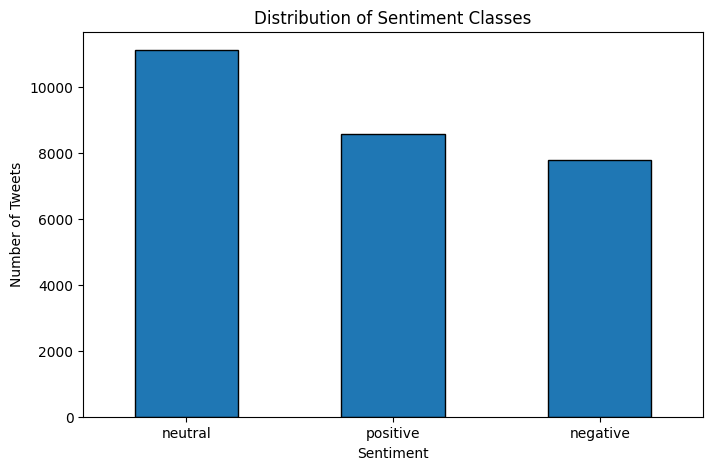

In [ ]:
sentiment_counts.plot(kind="bar", figsize=(8, 5), edgecolor="black")

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.show()

In [ ]:
df["text_length"] = df["text"].str.len()

df[["text", "text_length"]].sort_values(by="text_length", ascending=False).head(15)

,text,text_length
3137,Is so freaking bored on the bus. Hate being po...,141
27317,just saw an advert for ATTICS TO EDEN on tv o...,141
13895,Feeling madly sorry for myself... - ï¿½Iï¿½M S...,140
16850,"4 novos followers http://migre.me/SfN Sorry, t...",139
27066,"Jamie @ Sean Cody, up for some angry ****?: Ja...",139
2581,TODAy SUCKs - kisskass19: ï¿½you and katey bro...,139
12455,Have ordered the cuuutest invitations for my n...,139
25755,i am up - dont want to be though wish i had s...,138
13582,frustrated. I just found out our sitter isn`t ...,138
14192,Ok... No one was interested in my special. N...,138


In [ ]:
df["text_length"].value_counts()

,count
text_length,
41,308
48,301
46,301
42,298
45,295
...,...
4,8
3,5
139,4


In [ ]:
df.groupby("sentiment")["text_length"].agg(["mean", "median", "min", "max"])

,mean,median,min,max
sentiment,,,,
negative,70.488112,66.0,5,141
neutral,65.206800,59.0,3,141
positive,70.419133,67.0,5,138


<Axes: >

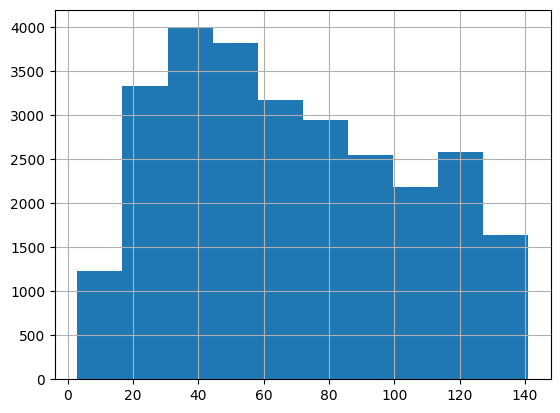

In [ ]:
df["text_length"].hist()

In [17]:
df["text_length"].describe()

,text_length
count,27480.000000
mean,68.330022
std,35.603870
min,3.000000
25%,39.000000
50%,64.000000
75%,97.000000
max,141.000000


<Axes: >

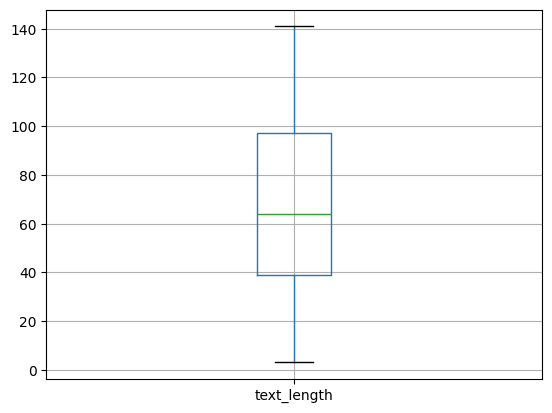

In [ ]:
df.boxplot(column="text_length")

У датасеті найбільше нейтральних твітів - 11 117, позитивних - 8 582, негативних - 7 781. Сильного дисбалансу класів немає.

Більшість постів мають довжину 20–80 символів, найчастіше - 30–50. Нейтральні пости в середньому коротші (65 символів), ніж позитивні та негативні (близько 70 символів).

### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [21]:
def tokenize_text(text):
    return word_tokenize(text.lower())

In [22]:
df["tokens"] = df["text"].apply(tokenize_text)

In [23]:
df["tokens"].head()

,tokens
0,"[i, `, d, have, responded, ,, if, i, were, going]"
1,"[sooo, sad, i, will, miss, you, here, in, san,..."
2,"[my, boss, is, bullying, me, ...]"
3,"[what, interview, !, leave, me, alone]"
4,"[sons, of, *, *, *, *, ,, why, couldn, `, t, t..."


In [ ]:
english_stopwords = stopwords.words("english")

In [25]:
", ".join(english_stopwords)

"a, about, above, after, again, against, ain, all, am, an, and, any, are, aren, aren't, as, at, be, because, been, before, being, below, between, both, but, by, can, couldn, couldn't, d, did, didn, didn't, do, does, doesn, doesn't, doing, don, don't, down, during, each, few, for, from, further, had, hadn, hadn't, has, hasn, hasn't, have, haven, haven't, having, he, he'd, he'll, her, here, hers, herself, he's, him, himself, his, how, i, i'd, if, i'll, i'm, in, into, is, isn, isn't, it, it'd, it'll, it's, its, itself, i've, just, ll, m, ma, me, mightn, mightn't, more, most, mustn, mustn't, my, myself, needn, needn't, no, nor, not, now, o, of, off, on, once, only, or, other, our, ours, ourselves, out, over, own, re, s, same, shan, shan't, she, she'd, she'll, she's, should, shouldn, shouldn't, should've, so, some, such, t, than, that, that'll, the, their, theirs, them, themselves, then, there, these, they, they'd, they'll, they're, they've, this, those, through, to, too, under, until, up, 

In [26]:
def remove_stopwords(tokens):
    return [word for word in tokens if word not in english_stopwords]

In [ ]:
df["tokens_without_stopwords"] = df["tokens"].apply(remove_stopwords)

In [28]:
df["tokens_without_stopwords"].head()

,tokens_without_stopwords
0,"[`, responded, ,, going]"
1,"[sooo, sad, miss, san, diego, !, !, !]"
2,"[boss, bullying, ...]"
3,"[interview, !, leave, alone]"
4,"[sons, *, *, *, *, ,, `, put, releases, alread..."


In [ ]:
stemmer = SnowballStemmer("english")

In [30]:
def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

In [31]:
df["stemmed_text"] = df["tokens_without_stopwords"].apply(stem_tokens)

In [32]:
df["stemmed_text"].head()

,stemmed_text
0,"[`, respond, ,, go]"
1,"[sooo, sad, miss, san, diego, !, !, !]"
2,"[boss, bulli, ...]"
3,"[interview, !, leav, alon]"
4,"[son, *, *, *, *, ,, `, put, releas, alreadi, ..."


In [69]:
X = df["processed_text"]
y = df["sentiment"]

In [ ]:
df["processed_text"] = df["stemmed_text"].apply(" ".join)

full_vectorizer = CountVectorizer(token_pattern=r"(?u)\b[a-z]{2,}\b")

X_full = full_vectorizer.fit_transform(X)

In [ ]:
total_words = X_full.sum()

for n in [1000, 3000, 5000, 10000]:
    vectorizer = CountVectorizer(max_features=n, token_pattern=r"(?u)\b[a-z]{2,}\b")

    X = vectorizer.fit_transform(df["processed_text"])

    coverage = X.sum() / total_words * 100

    print(
        f"max_features={n}, " f"vocabulary={X.shape[1]}, " f"coverage={coverage:.2f}%"
    )

max_features=1000, vocabulary=1000, coverage=73.28%
max_features=3000, vocabulary=3000, coverage=86.58%
max_features=5000, vocabulary=5000, coverage=90.96%
max_features=10000, vocabulary=10000, coverage=95.42%


Для Bag-of-Words обрано max_features=5000, оскільки такий словник покриває 90,96% усіх появ слів у корпусі. Збільшення словника до 10000 ознак підвищує покриття лише до 95,42%, тому 5000 ознак є прийнятним компромісом між розмірністю матриці та збереженням інформації.

In [ ]:
vectorizer = CountVectorizer(max_features=5000, token_pattern=r"(?u)\b[a-z]{2,}\b")

X_bow = vectorizer.fit_transform(df["processed_text"])

In [40]:
vectorizer.get_feature_names_out()[:30]

array(['aaaah', 'aaahhh', 'aah', 'aaron', 'ab', 'abandon', 'abbi', 'abil',
       'abit', 'abl', 'absolut', 'abt', 'abus', 'ac', 'academi', 'accept',
       'access', 'accid', 'accident', 'accomplish', 'accord', 'account',
       'acct', 'ace', 'ach', 'achiev', 'acid', 'ack', 'across', 'act'],
      dtype=object)

In [41]:
X_bow.shape

(27480, 5000)

In [ ]:
word_counts = pd.Series(X_bow.sum(axis=0).A1, index=vectorizer.get_feature_names_out())

word_counts.sort_values(ascending=False).head(20)

,0
day,2449
go,2383
get,1916
good,1599
work,1532
love,1484
like,1460
got,1260
http,1247
today,1155


### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
vectorizer = CountVectorizer(max_features=5000, token_pattern=r"(?u)\b[a-z]{2,}\b")

X_train_bow = vectorizer.fit_transform(X_train)

X_test_bow = vectorizer.transform(X_test)

In [47]:
print("Train:", X_train_bow.shape)
print("Test:", X_test_bow.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Train: (21984, 5000)
Test: (5496, 5000)
y_train: (21984,)
y_test: (5496,)


In [ ]:
model = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)

model.fit(X_train_bow, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [50]:
y_pred = model.predict(X_test_bow)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6866812227074236
              precision    recall  f1-score   support

    negative       0.70      0.62      0.66      1556
     neutral       0.63      0.72      0.67      2223
    positive       0.77      0.70      0.73      1717

    accuracy                           0.69      5496
   macro avg       0.70      0.68      0.69      5496
weighted avg       0.69      0.69      0.69      5496



In [ ]:
y_proba = model.predict_proba(X_test_bow)

roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8350624740608833


In [ ]:
tree_model = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, random_state=42)

tree_model.fit(X_train_bow, y_train)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, random_state=42)

In [ ]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)

['negative' 'neutral' 'positive']


In [ ]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train_bow, y_train_encoded)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
def evaluate_model(name, model, encoded=False):
    y_pred = model.predict(X_test_bow)
    y_proba = model.predict_proba(X_test_bow)

    if encoded:
        y_pred = label_encoder.inverse_transform(y_pred)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1-macro": f1_score(y_test, y_pred, average="macro"),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_proba,
            labels=label_encoder.classes_,
            multi_class="ovr",
            average="macro",
        ),
    }

In [ ]:
results = [
    evaluate_model("Logistic Regression", model),
    evaluate_model("Decision Tree", tree_model),
    evaluate_model("XGBoost", xgb_model, encoded=True),
]

results_df = pd.DataFrame(results)

results_df.sort_values(by="F1-macro", ascending=False).round(4)

,Model,Accuracy,F1-macro,ROC-AUC
0,Logistic Regression,0.6867,0.6879,0.8351
2,XGBoost,0.6725,0.6636,0.8201
1,Decision Tree,0.6201,0.5957,0.7361


In [ ]:
y_proba = xgb_model.predict_proba(X_test_bow)

auc_per_class = roc_auc_score(y_test_encoded, y_proba, multi_class="ovr", average=None)

pd.Series(auc_per_class, index=label_encoder.classes_)

,0
negative,0.826446
neutral,0.765520
positive,0.868348


Було порівняно три моделі класифікації: Logistic Regression, Decision Tree та XGBoost. Найкращий результат показала Logistic Regression (Accuracy = 68,67%, F1-macro = 0,6879, ROC-AUC = 0,8351). XGBoost продемонстрував дещо нижчі показники, а Decision Tree — найгірші. Отже, для подальшого аналізу обрано Logistic Regression, яка найкраще працює з поточними Bag-of-Words ознаками.

### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


In [ ]:
feature_names = vectorizer.get_feature_names_out()


feature_importance = pd.DataFrame(
    model.coef_.T, index=feature_names, columns=model.classes_
)

feature_importance.head()

,negative,neutral,positive
aaaa,-0.201061,0.289463,-0.088403
aaaah,0.266775,-0.116862,-0.149914
aaah,-0.170279,0.207929,-0.037650
aaawww,0.206243,-0.444614,0.238371
aah,0.521653,-0.535851,0.014198


In [60]:
feature_importance["positive"].nlargest(10)

,positive
awesom,2.627330
cute,2.624171
thank,2.476978
love,2.387447
glad,2.323273
amaz,2.272693
congratul,2.099535
enjoy,2.093090
nice,2.075578
excit,2.057396


In [61]:
feature_importance["positive"].nsmallest(10)

,positive
shame,-2.659559
sorri,-2.576275
sad,-2.528016
suck,-2.372886
bore,-2.219554
hate,-2.020776
horribl,-1.932672
jealous,-1.900260
miss,-1.893927
tire,-1.857753


In [62]:
feature_importance["negative"].nlargest(10)

,negative
sad,2.669859
suck,2.488502
sorri,2.440840
bore,2.357061
hate,2.299252
stupid,2.129632
fail,2.120547
miss,2.094839
worst,2.055435
exhaust,2.024932


In [63]:
feature_importance["negative"].nsmallest(10)

,negative
glad,-2.367477
awesom,-2.366154
love,-2.122443
beauti,-2.025816
thank,-1.941323
cute,-1.853918
welcom,-1.783105
amaz,-1.596927
enjoy,-1.582930
nice,-1.524552


In [64]:
feature_importance["neutral"].nlargest(10)

,neutral
indoor,1.613784
chan,1.552762
otherwis,1.281599
oooo,1.254421
parvo,1.226345
eu,1.142484
sarcast,1.127826
jst,1.125953
colorado,1.124819
sp,1.114500


In [65]:
feature_importance["neutral"].nsmallest(10)

,neutral
forum,-1.427004
congratul,-1.352870
wtf,-1.344818
thrill,-1.328869
proud,-1.272782
truli,-1.265963
incred,-1.258225
impati,-1.234449
product,-1.222416
nut,-1.180328


Аналіз коефіцієнтів Logistic Regression показав, що модель логічно розпізнає емоційно забарвлені слова. Для позитивного класу найбільші додатні коефіцієнти мають `awesom`, `love`, `thank`, а найбільші від'ємні - `shame`, `sad`, `suck`. Для негативного класу ситуація протилежна: `sad`, `hate`, `suck` підвищують його оцінку, а `love`, `glad`, `awesom` - знижують.

Для нейтрального класу найвпливовіші ознаки менш очевидні й можуть відображати особливості датасету. Загалом результати логічні, хоча модель враховує статистичні зв'язки слів із класами, а не їхній контекст чи справжнє значення.

### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



In [ ]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(X)
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()
)

In [72]:
print("\nTF-IDF:")
tfidf_df.round(2)


TF-IDF:


,00,000,000th,00am,00pm,01,02,024,02mxjj,03,...,½t,½tearï,½timo,½ureo,½v,½whi,½whyyi,½you,½z,½ï
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27475,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27476,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27477,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27478,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model